# Aggregation, joins and SQL from Python

After this block you can summarise tables with `GROUP BY` and `HAVING`, combine tables with inner and left joins, break a long question into named steps with subqueries and common table expressions, compute rankings, running totals and changes with window functions, and run all of this from Python notebooks and scripts with connections, cursors and parameters. The block serves the second and third learning outcomes of Session 3: *write SQL queries that aggregate and join* and *use common table expressions and window functions, and query the database from Python*.

The housing analyst from block 1 now asks questions that need many rows at once: how many listings and what average price per district, how many reviews per district once the review table is combined with the listings, which district is the most expensive *for each room type*, and how did the number of reviews develop month by month?

*Author: course team · Licence: CC BY 4.0, except the sections marked "Adapted from", which keep their source licence (named there).*

## Overview

| Section | What it covers |
|---|---|
| Setup | opening the course database, the helper `q` |
| Aggregation with GROUP BY and HAVING | aggregate functions, `GROUP BY`, `WHERE` against `HAVING`, `FILTER`, shares as averages of 0/1 values, grouping by an expression and by two columns, pitfalls: NULL groups, bare columns, no median |
| Joins: INNER JOIN and LEFT JOIN | cross, inner, left, right and full outer joins, joins on the course data, anti-joins, one-to-many joins that repeat rows, conditions in `ON` and in `WHERE`, joins on inequalities |
| Subqueries and common table expressions | one-value, list and table subqueries, `EXISTS` and correlated subqueries, `NOT IN` and NULL, CTEs as named steps, recursive CTEs |
| Window functions: ranking, running totals, comparison with the previous row | `OVER`, `PARTITION BY` and frames, `ROW_NUMBER`, `RANK`, `DENSE_RANK`, `NTILE`, ranking within groups, running totals, `LAG`, `LEAD`, `FIRST_VALUE`, moving averages, a row next to its group |
| Running SQL from Python | connections, cursors, parameters, SQL injection, `sqlite3.Row`, DataFrames with `read_sql_query` and `to_sql`, transactions, scripts, SQL written by a language model |
| Worked example | districts ranked by price within each room type, reviews per district and year, listings without a review |
| Check your understanding, Exercises, Debrief | five questions, twelve exercises in pairs, what to compare afterwards |

How the pieces combine in one analysis: tables are joined by key, grouped, ranked or compared with window functions, and the small result goes to Python.

```mermaid
flowchart LR
    T["tables<br/>listings, calendar, reviews"] --> J["JOIN<br/>combine by key"]
    J --> G["GROUP BY / HAVING<br/>one row per group"]
    G --> W["window functions<br/>rank, running total, LAG"]
    W --> P["Python: sqlite3,<br/>pandas.read_sql_query"]
    P --> S["script, chart, model"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Setup: open the course database

As in block 1: build the course database if it is missing, open a connection, and define the helper `q(sql, params)` that returns a query result as a DataFrame. The section on running SQL from Python explains every part of this cell.

In [2]:
import sqlite3
import subprocess
import sys

import pandas as pd

DB = Path("case-study/data/airbnb/airbnb.sqlite")
if not DB.exists():                     # build the course database once from the Parquet files
    subprocess.run([sys.executable, "sessions/03-sql/workbooks/make_airbnb_sqlite.py"], check=True)
con = sqlite3.connect(DB)


def q(sql, params=()):
    """Run an SQL query on the course database and return the result as a pandas DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

## Aggregation with GROUP BY and HAVING

### Aggregate functions and `GROUP BY`

An **aggregate function** reduces many values to one:

| Function | Result | pandas |
|---|---|---|
| `COUNT(*)` | number of rows | `.size()` |
| `COUNT(col)` | number of rows where `col` is not NULL | `.count()` |
| `COUNT(DISTINCT col)` | number of different values | `.nunique()` |
| `SUM(col)`, `AVG(col)` | sum and mean, NULLs skipped | `.sum()`, `.mean()` |
| `MIN(col)`, `MAX(col)` | smallest and largest value | `.min()`, `.max()` |
| `GROUP_CONCAT(col, ', ')` | the values joined into one text (SQLite; PostgreSQL: `STRING_AGG`) | `.agg(", ".join)` |

Without `GROUP BY`, an aggregate summarises the whole table in one row. `GROUP BY` splits the rows into groups with equal values of the grouping columns and computes the aggregates per group; the result has one row per group. Several aggregates can be computed in the same query, which takes more effort in pandas. Every column in `SELECT` must either be a grouping column or be inside an aggregate.

`WHERE` filters **rows before** grouping; `HAVING` filters **groups after** aggregation, for example "only districts with at least 300 listings". `FILTER (WHERE ...)` after an aggregate restricts that one aggregate to some rows of the group.

With `GROUP BY` and `HAVING`, the clause template of block 1 becomes:

```
SELECT <columns and aggregates>
FROM <table>
[WHERE <row condition>]
[GROUP BY <columns>]
[HAVING <group condition>]
[ORDER BY <columns>]
[LIMIT <n>] [OFFSET <k>];
```

By hand, with the small tables of block 1: grouping the three listings by `district` gives Mitte with `COUNT(*) = 2` and `COUNT(price) = 1`, and Neukölln with 1 and 1. `AVG(price)` for Mitte is 120, not 60: the missing price is skipped. `HAVING COUNT(*) >= 2` keeps only Mitte.

SQL is declarative: although `SUM(cost)` is written before `GROUP BY`, the database forms the groups first (logical order: `FROM`, `WHERE`, `GROUP BY`, `HAVING`, `SELECT`, `ORDER BY`, `LIMIT`).

*The table of aggregate functions with pandas equivalents, the clause template and the `WHERE` against `HAVING` comparison below are adapted from [Data 100, SQL I and SQL II](https://github.com/DS-100/fa23-course-notes/blob/main/sql_I/sql_I.qmd) (UC Berkeley Data 100, BSD 3-Clause).*

### Why it matters

Almost every business question is an aggregate: listings per district, average price per room type, reviews per month, the share of registered listings. `HAVING` with a minimum count prevents tiny groups from topping a ranking by chance: a district with five listings can have any average.

### Counting and averaging per district

Listings and average price per district. Prices are compared for **short stays** only (`minimum_nights < 28`): a third of the listings require a month or more, and their price means something else (Session 4). `ROUND(x, 1)` rounds to one decimal.

In [3]:
q("""
SELECT district,
       COUNT(*) AS n_listings,
       COUNT(price) FILTER (WHERE minimum_nights < 28) AS n_short_with_price,
       ROUND(AVG(price) FILTER (WHERE minimum_nights < 28), 1) AS avg_price,
       MIN(price) AS min_price, MAX(price) AS max_price
FROM listings
GROUP BY district
HAVING COUNT(*) >= 300            -- filter groups, not rows
ORDER BY avg_price DESC
""")

,district,n_listings,n_short_with_price,avg_price,min_price,max_price
0,Mitte,2268,1224,223.3,4.63,2269.0
1,Pankow,1562,825,202.1,5.31,1041.0
2,Treptow - Köpenick,459,271,197.3,4.41,4458.0
3,Friedrichshain-Kreuzberg,2119,1051,189.4,5.11,2956.0
4,Charlottenburg-Wilm.,1146,589,186.1,5.00,1040.0
5,Tempelhof - Schöneberg,675,363,173.1,6.16,1580.0
6,Lichtenberg,318,184,163.8,8.63,1083.0
7,Neukölln,1046,441,155.7,7.41,724.4


### `WHERE` against `HAVING`

**Predict before running.** Both queries count listings per room type and mention €40. Which one keeps only the room types whose *cheapest* listing costs more than €40, and which one counts only the listings above €40?

In [4]:
print(q("""
SELECT room_type, COUNT(*) AS n
FROM listings
WHERE price > 40                  -- rows: drop each listing at or below 40 euros, then group
GROUP BY room_type
"""))
q("""
SELECT room_type, COUNT(*) AS n
FROM listings
GROUP BY room_type
HAVING MIN(price) > 40            -- groups: keep a room type only if its cheapest listing is above 40 euros
""")

         room_type     n
0  Entire home/apt  3939
1       Hotel room    71
2     Private room  1489
3      Shared room    45


,room_type,n
0,Hotel room,76


`WHERE` removed single listings and kept every room type; `HAVING` kept all listings of the room types it kept, and dropped whole groups.

### Shares as averages of 0/1 values

A **share** is the average of a 0/1 value. In SQLite a comparison is already 0 or 1, so `AVG(license_status = 'registration number')` is the share of listings with a registration number. (In PostgreSQL, write `AVG((license_status = 'registration number')::int)`.)

In [5]:
q("""
SELECT room_type,
       COUNT(*) AS n,
       ROUND(AVG(license_status = 'registration number'), 3) AS share_registered,
       COUNT(*) FILTER (WHERE minimum_nights >= 28) AS n_medium_term
FROM listings
GROUP BY room_type
ORDER BY n DESC
""")

,room_type,n,share_registered,n_medium_term
0,Entire home/apt,7073,0.341,2509
1,Private room,3003,0.394,1065
2,Hotel room,76,0.000,8
3,Shared room,69,0.043,5


Hotel rooms and shared rooms (hostel beds) almost never show a registration number: the Berlin registration rule concerns private flats, while hotels and hostels are commercial businesses regulated differently, so a missing number is not a violation there. One aggregate table, read with knowledge of the domain, prevents a wrong headline.

> **Note.** Integer division: in SQLite and PostgreSQL, `SUM(a) / COUNT(*)` with two integers is an integer division and returns 0 for any share below 1. Write `SUM(a) * 1.0 / COUNT(*)` or use `AVG`.

### Grouping by an expression and by two columns

`GROUP BY` accepts any expression, for example the `CASE` category of block 1, and several columns: then each combination is a group.

In [6]:
q("""
SELECT CASE WHEN minimum_nights < 7  THEN '1: under a week'
            WHEN minimum_nights < 28 THEN '2: a week or more'
            ELSE '3: a month or more' END AS stay_type,
       room_type,
       COUNT(*) AS n
FROM listings
WHERE room_type IN ('Entire home/apt', 'Private room')
GROUP BY stay_type, room_type
ORDER BY stay_type, room_type
""")

,stay_type,room_type,n
0,1: under a week,Entire home/apt,4202
1,1: under a week,Private room,1854
2,2: a week or more,Entire home/apt,361
3,2: a week or more,Private room,83
4,3: a month or more,Entire home/apt,2510
5,3: a month or more,Private room,1066


### Pitfalls of grouping

#### NULL forms its own group

Grouping by a column with missing values gives one group for all NULLs. `bedrooms` is missing for some listings:

In [7]:
q("SELECT bedrooms, COUNT(*) AS n FROM listings GROUP BY bedrooms ORDER BY bedrooms LIMIT 4")

,bedrooms,n
0,NaN,2715
1,0.0,3
2,1.0,4921
3,2.0,1734


#### Bare columns

A **bare column** is a column in `SELECT` that is neither grouped nor aggregated (the SQLite documentation uses this name). It is an error in PostgreSQL. SQLite accepts it and returns the value from *some* row of the group; only with a single `MIN` or `MAX` does SQLite promise the row that holds the minimum or maximum. Do not rely on this: it does not run on other databases.

In [8]:
q("""
SELECT district, id, MAX(price) AS max_price      -- id is a bare column: SQLite-only behaviour
FROM listings
GROUP BY district
ORDER BY max_price DESC
LIMIT 3
""")

,district,id,max_price
0,Steglitz - Zehlendorf,1043552887218608966,10025.0
1,Spandau,1704420758533033977,7999.2
2,Treptow - Köpenick,1199052323714124847,4458.0


#### No median function

SQLite has no median function. Where you need one, compute the groups' rows in SQL and the median in pandas, or build it from window functions (exercise 2.10).

### In practice

- **Eurostat and national statistical offices** publish tourism statistics, such as nights spent per region and month, computed from the reports of individual accommodation businesses; each published cell is a `GROUP BY` result.
- **Hospital comparisons** such as Care Compare of the US Centers for Medicare & Medicaid Services do not publish a measure when a hospital has too few cases, which is the idea of `HAVING COUNT(*) >= k`.

> **Note.** `AVG` skips NULLs, so `AVG(price)` is the average over the listings that show a price, not over all listings (block 1, NULL values).

> 📖 **Read more:** [extras/03-data100-sql-having-cleaning-joins.ipynb](extras/03-data100-sql-having-cleaning-joins.ipynb) (UC Berkeley Data 100, BSD 3-Clause): `HAVING` against `WHERE` on a small menu table, text matching, `CAST` and `CASE`.

## Joins: INNER JOIN and LEFT JOIN

### What a join is

Normalised data are spread over several tables. A **join** combines rows of two tables whose key columns match. The join is written in the `FROM` clause: "select my data from tables that have been joined together".

```
SELECT <columns>
FROM table_1
    JOIN table_2
    ON table_1.key = table_2.key;
```

Short **aliases** (`FROM listings AS l`) say which table a column comes from: `l.district`, `r.n_reviews`. When the key has the same name in both tables, `JOIN t2 USING (key)` is a shorter form of `ON`.

### The join types

The Data 100 course notes show the join types on two small tables of cats, `s` (names) and `t` (breeds), linked by `id`:

![Two tables s and t of cats with an id column](extras/images/cats.png)

- A **cross join** pairs *every* row of `s` with *every* row of `t`, whether the keys match or not (the Cartesian product): 4 × 4 = 16 rows. It needs no `ON`.

![Cross join of s and t](extras/images/cross.png)

- An **inner join** keeps only the pairs whose keys match: a cross join followed by removing the rows whose keys differ. Rows without a partner in the other table disappear. This is the join that pandas `merge` does by default.

![Inner join of s and t](extras/images/inner.png)

- A **left (outer) join** keeps every row of the left table; where no partner exists, the columns of the right table are NULL.

![Left join of s and t](extras/images/left.png)

- A **right join** keeps every row of the right table, and a **full outer join** keeps the unmatched rows of both tables. SQLite supports both since version 3.39 (2022); older SQLite versions, and the Data 100 notes written for them, do not. A right join is a left join with the tables swapped, so most people write left joins only.

![Right join of s and t](extras/images/right.png)

![Full outer join of s and t](extras/images/full.png)

*Figures and the cats example from [Data 100, SQL II](https://github.com/DS-100/fa23-course-notes/blob/main/sql_II/sql_II.qmd) (UC Berkeley Data 100, BSD 3-Clause). The note on RIGHT and FULL joins in SQLite is updated for SQLite 3.39 and later.*

### Why it matters

The join type decides which rows survive and therefore which population a number describes. Many wrong numbers in reports come from an unintended inner join, which drops unmatched rows silently, or from a join on a key that is not unique, which repeats rows.

### Counting the rows of each join type

The next cell builds the two cat tables in an in-memory database and counts the rows of each join type. **Predict before running:** how many rows does each join return?

In [9]:
cats = sqlite3.connect(":memory:")
cats.executescript("""
CREATE TABLE s (id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE t (id INTEGER PRIMARY KEY, breed TEXT);
INSERT INTO s VALUES (0, 'Apricot'), (1, 'Boots'), (2, 'Cally'), (4, 'Eugene');
INSERT INTO t VALUES (1, 'persian'), (2, 'ragdoll'), (4, 'bengal'), (5, 'persian');
""")
joins = {
    "CROSS JOIN": "SELECT * FROM s CROSS JOIN t",
    "INNER JOIN": "SELECT * FROM s JOIN t ON s.id = t.id",
    "LEFT JOIN": "SELECT * FROM s LEFT JOIN t ON s.id = t.id",
    "RIGHT JOIN": "SELECT * FROM s RIGHT JOIN t ON s.id = t.id",
    "FULL OUTER JOIN": "SELECT * FROM s FULL OUTER JOIN t ON s.id = t.id",
}
{name: len(pd.read_sql_query(sql, cats)) for name, sql in joins.items()}

{'CROSS JOIN': 16,
 'INNER JOIN': 3,
 'LEFT JOIN': 4,
 'RIGHT JOIN': 4,
 'FULL OUTER JOIN': 5}

The full outer join, row by row: Apricot has no breed, and the persian cat with id 5 has no name.

In [10]:
pd.read_sql_query("SELECT s.id AS s_id, s.name, t.id AS t_id, t.breed FROM s FULL OUTER JOIN t ON s.id = t.id", cats)

,s_id,name,t_id,breed
0,0.0,Apricot,NaN,NaN
1,1.0,Boots,1.0,persian
2,2.0,Cally,2.0,ragdoll
3,4.0,Eugene,4.0,bengal
4,NaN,NaN,5.0,persian


### Joins on the course data

Each review month gets the district of its listing: reviews in 2025 per district. The figure shows the same inner and left join on the small tables of block 1.

![Inner and left join of a small listings and reviews table](../figures/join-types.png)

In [11]:
q("""
SELECT l.district, SUM(r.n_reviews) AS reviews_2025, COUNT(DISTINCT l.id) AS listings_reviewed
FROM listings AS l
JOIN reviews AS r ON r.listing_id = l.id
WHERE r.month BETWEEN '2025-01-01' AND '2025-12-01'
GROUP BY l.district
ORDER BY reviews_2025 DESC
LIMIT 3
""")

,district,reviews_2025,listings_reviewed
0,Mitte,26089,1110
1,Friedrichshain-Kreuzberg,24683,1125
2,Pankow,16910,824


The share of nights still available in July and August 2026 per district joins listings with the 3.8 million calendar rows. A night that is not available is either booked or blocked by the host; the calendar does not say which, so a low share is an upper bound on demand, not a measure of it.

In [12]:
q("""
SELECT l.district, COUNT(*) AS nights, ROUND(AVG(c.available), 3) AS share_available
FROM listings AS l
JOIN calendar AS c ON c.listing_id = l.id
WHERE c.date BETWEEN '2026-07-01' AND '2026-08-31'
GROUP BY l.district
ORDER BY share_available
LIMIT 3
""")

,district,nights,share_available
0,Neukölln,63594,0.255
1,Friedrichshain-Kreuzberg,129194,0.317
2,Pankow,95366,0.323


### Anti-joins: rows without a partner

An **anti-join** (a common name, not an SQL keyword) keeps the rows of one table that have **no** partner in the other. In SQL it is a left join combined with `WHERE right.key IS NULL`. In both directions: listings without any review, and review rows whose listing is not in `listings` (the 57 vanished listings of block 1). The last query counts the rows an inner join keeps.

In [13]:
print(q("""
SELECT COUNT(*) AS listings_without_review
FROM listings AS l
LEFT JOIN reviews AS r ON r.listing_id = l.id
WHERE r.listing_id IS NULL
"""))
print(q("""
SELECT COUNT(*) AS review_rows, COUNT(DISTINCT r.listing_id) AS listings, SUM(r.n_reviews) AS reviews
FROM reviews AS r
LEFT JOIN listings AS l ON l.id = r.listing_id
WHERE l.id IS NULL
"""))
q("SELECT COUNT(*) AS rows_after_inner_join, (SELECT COUNT(*) FROM reviews) AS rows_in_reviews "
  "FROM reviews AS r JOIN listings AS l ON l.id = r.listing_id")

   listings_without_review
0                     2003
   review_rows  listings  reviews
0          499        57     4932


,rows_after_inner_join,rows_in_reviews
0,180157,180656


The inner join silently drops the 499 review rows (4,932 reviews) of the 57 vanished listings: only the comparison with the row count of the table shows it.

### One-to-many joins repeat rows

After `listings JOIN reviews`, a listing with 100 review months appears 100 times, so `AVG(l.price)` is no longer the average price of a listing but an average weighted by review months. **Predict before running:** will the average price after the join be higher or lower than the average over one row per listing?

In [14]:
q("""
SELECT 'after the join' AS version, COUNT(*) AS n_rows, ROUND(AVG(l.price), 1) AS avg_price
FROM listings AS l JOIN reviews AS r ON r.listing_id = l.id
WHERE l.minimum_nights < 28
UNION ALL
SELECT 'one row per listing', COUNT(*), ROUND(AVG(price), 1)
FROM listings WHERE minimum_nights < 28 AND number_of_reviews > 0
""")

,version,n_rows,avg_price
0,after the join,163825,183.2
1,one row per listing,6167,191.7


(`UNION ALL` stacks the rows of two queries with the same columns.) After the join, a listing counts once per review month. The weighted average is lower, so the listings with many review months are cheaper on average than the others. Aggregate the "many" side first (with a CTE, in the next section), or compare `COUNT(*)` with `COUNT(DISTINCT key)`.

### Conditions in `ON` and in `WHERE`

A condition in `WHERE` turns a left join back into an inner join. `listings l LEFT JOIN reviews r ... WHERE r.month >= '2026-01-01'` keeps only listings with a review in 2026, because `r.month` is NULL for all others. Put such conditions into `ON` if unmatched rows must stay:

In [15]:
q("""
SELECT 'condition in WHERE' AS version, COUNT(DISTINCT l.id) AS listings
FROM listings AS l LEFT JOIN reviews AS r ON r.listing_id = l.id
WHERE r.month >= '2026-01-01'
UNION ALL
SELECT 'condition in ON', COUNT(DISTINCT l.id)
FROM listings AS l LEFT JOIN reviews AS r ON r.listing_id = l.id AND r.month >= '2026-01-01'
""")

,version,listings
0,condition in WHERE,4743
1,condition in ON,10221


### Joins on inequalities

The `ON` condition does not have to be an equality. Data 100's example joins students with teachers where the student is older than the teacher:

![Students and teachers](extras/images/student.png)

![An inequality join: each student with every teacher younger than them](extras/images/inequality.png)

*Figures from [Data 100, SQL II](https://github.com/DS-100/fa23-course-notes/blob/main/sql_II/sql_II.qmd) (UC Berkeley Data 100, BSD 3-Clause).*

On the course data, an inequality join assigns each listing to a price band from a small lookup table. `WITH bands(...) AS (VALUES ...)` writes a small table inline (a common table expression, the topic of the next section).

In [16]:
q("""
WITH bands(band, lo, hi) AS (VALUES ('under 80', 0, 80), ('80 to 150', 80, 150), ('150 and more', 150, 1e9))
SELECT b.band, COUNT(*) AS n_listings
FROM listings AS l
JOIN bands AS b ON l.price >= b.lo AND l.price < b.hi     -- an inequality join
WHERE l.minimum_nights < 28
GROUP BY b.band
ORDER BY MIN(b.lo)
""")

,band,n_listings
0,under 80,578
1,80 to 150,1879
2,150 and more,2845


### In practice

- **Marketing analysts** join transactions with customer attributes; a customer without transactions disappears in an inner join and must be kept with a left join if "inactive customers" are part of the question.
- **Epidemiological record linkage**, for example linking cancer registries with mortality registers, keeps unmatched records and analyses them separately, because who fails to link is itself informative.

> 📖 **Read more:** [extras/03-data100-sql-having-cleaning-joins.ipynb](extras/03-data100-sql-having-cleaning-joins.ipynb) (UC Berkeley Data 100, BSD 3-Clause): star schemas and every join type with figures.

## Subqueries and common table expressions

### Subqueries

A **subquery** is a query in parentheses inside another query. It can return

- one value: `WHERE price > (SELECT AVG(price) FROM listings)`;
- a list: `WHERE id IN (SELECT listing_id FROM reviews WHERE ...)`;
- a whole table: `FROM (SELECT ...) AS t`.

`EXISTS (subquery)` is true when the subquery returns at least one row; `NOT EXISTS` when it returns none. A subquery that refers to a column of the outer query (`WHERE r.listing_id = l.id`) is **correlated**: it is evaluated once per outer row.

How many listings are more expensive than the average listing (a one-value subquery), and how many were reviewed in 2026 (a list subquery)?

In [17]:
q("""
SELECT (SELECT COUNT(*) FROM listings WHERE price > (SELECT AVG(price) FROM listings)) AS above_average,
       (SELECT COUNT(*) FROM listings
        WHERE id IN (SELECT listing_id FROM reviews WHERE month >= '2026-01-01'))   AS reviewed_in_2026
""")

,above_average,reviewed_in_2026
0,2577,4743


`EXISTS` and `NOT EXISTS` with a correlated subquery: the private rooms in Pankow with and without any review month. This is the safe way to find rows without a partner.

In [18]:
q("""
SELECT
  (SELECT COUNT(*) FROM listings AS l
   WHERE l.district = 'Pankow' AND l.room_type = 'Private room'
     AND EXISTS (SELECT 1 FROM reviews AS r WHERE r.listing_id = l.id))     AS with_reviews,
  (SELECT COUNT(*) FROM listings AS l
   WHERE l.district = 'Pankow' AND l.room_type = 'Private room'
     AND NOT EXISTS (SELECT 1 FROM reviews AS r WHERE r.listing_id = l.id)) AS without_reviews
""")

,with_reviews,without_reviews
0,270,59


> **Note.** `WHERE id NOT IN (SELECT listing_id FROM ...)` behaves unexpectedly when the subquery returns a NULL (remember the three-valued logic of block 1). Find rows without a partner with `NOT EXISTS (...)` or with a left join and `IS NULL`.

### Common table expressions

A **common table expression** (CTE), written `WITH name AS (SELECT ...)`, gives an intermediate result a name; later parts of the query use it like a table. Several CTEs separated by commas turn a long query into a sequence of readable steps, much like intermediate variables in Python.

Real questions take several steps: first aggregate the review months per listing, then compare listings; first compute a value per district, then rank the districts. Nested subqueries become hard to read after two levels; named steps can be read, tested and changed one at a time.

The one-to-many trap of the joins section, done correctly with a CTE: first one row per listing (reviews summed), then the join, so that every listing counts once.

In [19]:
q("""
WITH per_listing AS (                       -- step 1: one row per listing
    SELECT listing_id, SUM(n_reviews) AS n_reviews, MIN(month) AS first_month
    FROM reviews
    GROUP BY listing_id
)
SELECT l.room_type,                          -- step 2: join and aggregate
       COUNT(*) AS listings,
       ROUND(AVG(l.price), 1) AS avg_price,
       ROUND(AVG(p.n_reviews), 1) AS avg_reviews
FROM listings AS l
JOIN per_listing AS p ON p.listing_id = l.id
WHERE l.minimum_nights < 28
GROUP BY l.room_type
ORDER BY listings DESC
""")

,room_type,listings,avg_price,avg_reviews
0,Entire home/apt,4291,224.0,82.2
1,Private room,1752,113.2,74.7
2,Hotel room,64,213.9,120.3
3,Shared room,60,56.8,151.3


A CTE can be tested on its own: run `SELECT * FROM per_listing LIMIT 5` with the same `WITH` clause before you write step 2.

### Recursive CTEs

`WITH RECURSIVE` lets a CTE refer to itself, which repeats a step until it returns no more rows. A recursive CTE has two parts joined by `UNION ALL`: a starting row, and a step that produces the next row from the previous one. The step repeats until its `WHERE` stops it. Here it generates the twelve months of 2020 as text dates, so that the monthly review totals can be joined to a complete list of months: a month without any review would still appear, with 0.

In [20]:
q("""
WITH RECURSIVE months(month) AS (
    SELECT '2020-01-01'                                   -- start
    UNION ALL
    SELECT date(month, '+1 month') FROM months            -- step
    WHERE month < '2020-12-01'                            -- stop
), totals AS (
    SELECT month, SUM(n_reviews) AS n FROM reviews GROUP BY month
)
SELECT m.month, COALESCE(t.n, 0) AS reviews
FROM months AS m LEFT JOIN totals AS t ON t.month = m.month
ORDER BY m.month
""").T

,0,1,2,3,4,5,6,7,8,9,10,11
month,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01
reviews,3094,3127,1950,226,464,1202,2136,2971,2244,1826,881,683


### In practice

- **Analysts** write long reports as chains of CTEs, one per step, and check each step on its own by selecting from it.
- **Hierarchies**, such as an employee's chain of managers or the customs nomenclature from chapter to heading in the final project, are walked with recursive CTEs.

## Window functions: ranking, running totals, comparison with the previous row

### What a window function is

A **window function** computes a value for each row from a set of related rows, the **window**, without collapsing them into one row. This is the difference from `GROUP BY`, which returns one row per group. The window is defined after `OVER`:

- `PARTITION BY room_type` restricts the window to rows of the same room type (like a group);
- `ORDER BY avg_price DESC` sorts the rows inside the window;
- an optional **frame** such as `ROWS BETWEEN 2 PRECEDING AND CURRENT ROW` limits the window to nearby rows (for moving averages).

The function decides what is computed:

| Function | Value for each row |
|---|---|
| `ROW_NUMBER()` | 1, 2, 3, ... in the window order; ties broken arbitrarily |
| `RANK()` | ties share a number, then a gap (1, 1, 3) |
| `DENSE_RANK()` | ties share a number, no gap (1, 1, 2) |
| `NTILE(k)` | the number of the group when the rows are split into *k* groups of nearly equal size |
| `SUM(x) OVER (ORDER BY t)` | running total up to this row |
| `AVG(x) OVER (PARTITION BY g)` | the group average next to each row |
| `LAG(x)`, `LAG(x, k)` | the value one row (or *k* rows) earlier; `LEAD` looks forward |
| `FIRST_VALUE(x)` | the first value in the window |

Window functions are evaluated after `WHERE`, `GROUP BY` and `HAVING`. A filter on their result, such as "rank 1 only", must therefore be placed one query level higher, in the next CTE or in the outer query.

By hand. Average prices per room type and district (invented numbers):

| room_type | district | avg_price | `RANK() OVER (PARTITION BY room_type ORDER BY avg_price DESC)` | `DENSE_RANK()` | `ROW_NUMBER()` |
|---|---|---|---|---|---|
| Entire home/apt | Mitte | 210 | 1 | 1 | 1 |
| Entire home/apt | Pankow | 210 | 1 | 1 | 2 |
| Entire home/apt | Neukölln | 160 | 3 | 2 | 3 |
| Private room | Mitte | 115 | 1 | 1 | 1 |
| Private room | Neukölln | 95 | 2 | 2 | 2 |

The numbering restarts for each room type (partition). Mitte and Pankow tie for entire homes; `RANK` then skips to 3, `DENSE_RANK` continues with 2, and `ROW_NUMBER` breaks the tie arbitrarily.

### Why it matters

Rankings within groups, running totals, changes against the previous period, moving averages and "this row compared with its group" are standard analytical questions. Without window functions they need self-joins or loops in Python; with them they are one readable query that the database executes over all rows.

### Ranking functions and ties

The three ranking functions side by side on a small table with a tie. **Predict before running:** which numbers do Pankow and Neukölln get in each column?

In [21]:
pd.read_sql_query("""
WITH prices(district, avg_price) AS (VALUES ('Mitte', 210), ('Pankow', 210), ('Neukölln', 160), ('Spandau', 120))
SELECT district, avg_price,
       ROW_NUMBER() OVER (ORDER BY avg_price DESC) AS row_number,
       RANK()       OVER (ORDER BY avg_price DESC) AS rank,
       DENSE_RANK() OVER (ORDER BY avg_price DESC) AS dense_rank,
       NTILE(2)     OVER (ORDER BY avg_price DESC) AS half
FROM prices
""", cats)

,district,avg_price,row_number,rank,dense_rank,half
0,Mitte,210,1,1,1,1
1,Pankow,210,2,1,1,1
2,Neukölln,160,3,3,2,2
3,Spandau,120,4,4,3,2


### Ranking within groups

The three most expensive districts for each room type, by average short-stay price, in three named steps. The query is also in [`sql/02-rank-districts-by-price.sql`](sql/02-rank-districts-by-price.sql).

```mermaid
flowchart TB
    T["listings"] --> S["CTE short_stays:<br/>WHERE minimum_nights &lt; 28"]
    S --> G["CTE per_district:<br/>GROUP BY room_type, district<br/>HAVING COUNT(*) &gt;= 30"]
    G --> W["CTE ranked:<br/>RANK() OVER (PARTITION BY<br/>room_type ORDER BY avg_price DESC)"]
    W --> F["outer query:<br/>WHERE rnk &lt;= 3"]
```

In [22]:
q("""
WITH short_stays AS (                      -- step 1: the listings the question is about
    SELECT district, room_type, price
    FROM listings
    WHERE minimum_nights < 28 AND price IS NOT NULL
      AND room_type IN ('Entire home/apt', 'Private room')
), per_district AS (                       -- step 2: one row per room type and district
    SELECT room_type, district, COUNT(*) AS n_listings, ROUND(AVG(price), 1) AS avg_price
    FROM short_stays
    GROUP BY room_type, district
    HAVING COUNT(*) >= 30
), ranked AS (                             -- step 3: rank inside each room type
    SELECT *, RANK() OVER (PARTITION BY room_type ORDER BY avg_price DESC) AS rnk
    FROM per_district
)
SELECT room_type, rnk, district, n_listings, avg_price
FROM ranked
WHERE rnk <= 3                             -- filter one level up
ORDER BY room_type, rnk
""")

,room_type,rnk,district,n_listings,avg_price
0,Entire home/apt,1,Spandau,47,417.3
1,Entire home/apt,2,Steglitz - Zehlendorf,93,310.2
2,Entire home/apt,3,Mitte,883,250.1
3,Private room,1,Mitte,291,160.7
4,Private room,2,Charlottenburg-Wilm.,222,123.0
5,Private room,3,Pankow,156,112.6


Is Spandau's first place for entire homes real? A single extreme price can lift the average of a small group. The most expensive short-stay listings there:

In [23]:
q("""
SELECT id, price FROM listings
WHERE district = 'Spandau' AND room_type = 'Entire home/apt' AND minimum_nights < 28
ORDER BY price DESC LIMIT 3
""")

,id,price
0,1704420758533033977,7999.20
1,1023242605203063841,1000.00
2,1688242244955350911,680.14


One listing at several thousand euros a night is enough. The `HAVING` threshold protects against tiny groups, not against single extreme values; Session 4 treats such outliers.

### Running totals, changes and moving averages

A **running total** is the sum of all values up to the current row; a **moving average** is the average of the current row and a fixed number of neighbouring rows. Reviews per month around the first COVID-19 lockdown, the course's proxy for demand. `LAG(n) OVER (ORDER BY month)` is the previous month's value, and `ROWS 2 PRECEDING` is a frame of the current row and the two before it.

In [24]:
q("""
WITH monthly AS (
    SELECT month, SUM(n_reviews) AS n
    FROM reviews
    WHERE month BETWEEN '2019-12-01' AND '2020-06-01'
    GROUP BY month
)
SELECT month, n,
       SUM(n) OVER (ORDER BY month)                         AS running_total,
       n - LAG(n) OVER (ORDER BY month)                     AS change,
       ROUND(AVG(n) OVER (ORDER BY month ROWS 2 PRECEDING)) AS moving_avg_3m
FROM monthly
ORDER BY month
""")

,month,n,running_total,change,moving_avg_3m
0,2019-12-01,3160,3160,NaN,3160.0
1,2020-01-01,3094,6254,-66.0,3127.0
2,2020-02-01,3127,9381,33.0,3127.0
3,2020-03-01,1950,11331,-1177.0,2724.0
4,2020-04-01,226,11557,-1724.0,1768.0
5,2020-05-01,464,12021,238.0,880.0
6,2020-06-01,1202,13223,738.0,631.0


`LAG` has no previous row for December, so the change is NULL (shown as `NaN` in pandas). The moving average uses fewer than three months at the start. Read the April 2020 row: the collapse of travel is visible in one number (Session 12 models this break).

![Reviews per year 2012-2025 with the year-over-year change computed by a window function](../figures/reviews-per-year-window.png)

#### A running total that restarts each year

A `PARTITION BY` in a running total restarts the total in each partition, here each year: [`sql/03-reviews-running-total.sql`](sql/03-reviews-running-total.sql) computes `SUM(n_reviews) OVER (PARTITION BY substr(month, 1, 4) ORDER BY month)`. The next cell reads that file and plots the running total within selected years.

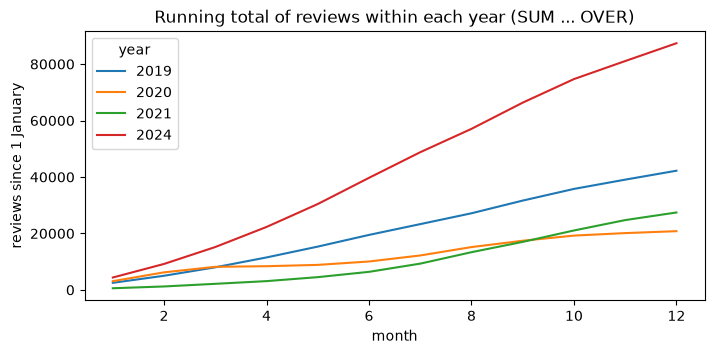

In [25]:
monthly = q(Path("sessions/03-sql/workbooks/sql/03-reviews-running-total.sql").read_text())
monthly["month"] = pd.to_datetime(monthly["month"])
ax = (monthly.assign(year=monthly["month"].dt.year, month_no=monthly["month"].dt.month)
      .query("year in [2019, 2020, 2021, 2024]")
      .pivot(index="month_no", columns="year", values="running_total_year")
      .plot(figsize=(8, 3.5), title="Running total of reviews within each year (SUM ... OVER)"))
ax.set(xlabel="month", ylabel="reviews since 1 January");

#### Looking ahead and back to the start: `LEAD` and `FIRST_VALUE`

`LEAD(x)` is the value of the next row, the mirror image of `LAG`, and `FIRST_VALUE(x)` is the value of the first row of the window. On the monthly totals of 2020: the next month's value, and each month as a share of January.

In [26]:
q("""
WITH monthly AS (SELECT month, SUM(n_reviews) AS n FROM reviews
                 WHERE month BETWEEN '2020-01-01' AND '2020-06-01' GROUP BY month)
SELECT month, n,
       LEAD(n) OVER (ORDER BY month)                                AS next_month,
       ROUND(1.0 * n / FIRST_VALUE(n) OVER (ORDER BY month), 2)     AS share_of_january
FROM monthly
""")

,month,n,next_month,share_of_january
0,2020-01-01,3094,3127.0,1.00
1,2020-02-01,3127,1950.0,1.01
2,2020-03-01,1950,226.0,0.63
3,2020-04-01,226,464.0,0.07
4,2020-05-01,464,1202.0,0.15
5,2020-06-01,1202,NaN,0.39


### A row next to its group

`AVG(...) OVER (PARTITION BY district)` places the district average next to each listing without collapsing the rows. Here: the share of available nights in the coming year per listing, compared with its district.

In [27]:
q("""
WITH per_listing AS (                         -- one row per listing: share of available nights
    SELECT l.id, l.district, AVG(c.available) AS share_free
    FROM listings AS l JOIN calendar AS c ON c.listing_id = l.id
    GROUP BY l.id, l.district
), compared AS (                              -- window: each listing next to its district
    SELECT *, AVG(share_free) OVER (PARTITION BY district) AS district_avg
    FROM per_listing
)
SELECT district,
       ROUND(MIN(district_avg), 3) AS avg_share_free,
       ROUND(AVG(share_free = 0), 3) AS share_never_available,
       COUNT(*) FILTER (WHERE share_free - district_avg > 0.5) AS far_freer_than_district
FROM compared
GROUP BY district
ORDER BY avg_share_free
LIMIT 3
""")

,district,avg_share_free,share_never_available,far_freer_than_district
0,Neukölln,0.285,0.425,162
1,Tempelhof - Schöneberg,0.363,0.244,86
2,Friedrichshain-Kreuzberg,0.374,0.317,341


A large share of listings in these districts has not a single available night in the coming year. That is not a sign of booming demand: a calendar that is closed for a whole year usually means the listing is not offered at all.

### In practice

- **Finance teams** compute month-over-month growth and cumulative revenue with `LAG` and running sums for management reports.
- **Health-services research** with claims data uses `LAG` over the admissions of each patient to measure the time to readmission, the basis of readmission indicators.
- In pandas, `groupby(...).rank()` corresponds to `RANK() OVER (PARTITION BY ...)`, `cumsum()` to a running `SUM`, `diff()` to `n - LAG(n)`, `shift()` to `LAG`, and `groupby(...).transform("mean")` to `AVG(...) OVER (PARTITION BY ...)`.

> **Note.** `RANK`, `DENSE_RANK` and `ROW_NUMBER` differ only when there are ties, so a bug may go unnoticed for a long time. Decide explicitly how ties should be handled, and add a second sort key (for example `ORDER BY avg_price DESC, district`) when you need a reproducible order.

> **Note.** `WHERE RANK() OVER (...) = 1` is an error: `WHERE` is evaluated before window functions. Compute the rank in a CTE and filter in the next step.

## Running SQL from Python

### Connections, cursors, parameters and transactions

The module `sqlite3` is part of Python's standard library and follows the Python database interface (DB-API 2.0), so the same pattern works for other databases. Four objects and ideas cover almost all work:

- **Connection.** `con = sqlite3.connect("file.sqlite")` opens the file (and creates it if it does not exist). `con.close()` closes it.
- **Cursor.** `cur = con.cursor()` creates a cursor, the object that executes a statement and walks through its result: `cur.execute(sql)`, then `cur.fetchone()` (the next row as a tuple), `cur.fetchmany(n)`, `cur.fetchall()` (all remaining rows as a list of tuples) or a `for` loop over `cur`. `con.execute(sql)` is a shortcut that creates the cursor for you.
- **Parameters.** Values that change between runs are passed separately from the SQL text, with placeholders: `?` filled from a tuple, or `:name` filled from a dictionary. SQLite receives the values as data, so they can never be read as SQL.
- **Transactions.** Statements that change data (`INSERT`, `UPDATE`, `DELETE`) are kept in a transaction until `con.commit()`; `con.rollback()` undoes them. `with con: ...` commits at the end of the block, or rolls back if an error occurs (it does not close the connection).

pandas adds two functions: `pd.read_sql_query(sql, con, params=...)` runs a query and returns a DataFrame; `DataFrame.to_sql(name, con)` writes a DataFrame into a table.

```mermaid
sequenceDiagram
    participant P as Python
    participant C as sqlite3 connection
    participant F as SQLite file
    P->>C: execute(sql, parameters)
    C->>F: read and write pages of the file
    F-->>C: result rows
    C-->>P: tuples (fetchall) or a DataFrame (read_sql_query)
```

### Why it matters

The database does the filtering, joining and aggregation on all rows; Python receives a small result for plotting and modelling, and a script can repeat the whole analysis with one command. Parameters protect against **SQL injection**, an attack in which text entered by a user changes the meaning of a query.

### Cursors and fetching

`fetchone()` returns the next row, `fetchall()` the remaining rows. A cursor remembers its position.

In [28]:
cur = con.cursor()
cur.execute("SELECT district, COUNT(*) FROM listings GROUP BY district ORDER BY 2 DESC")
print(cur.fetchone())          # the first row, as a tuple
print(cur.fetchmany(2))        # the next two rows
print(len(cur.fetchall()), "rows left")

('Mitte', 2268)
[('Friedrichshain-Kreuzberg', 2119), ('Pankow', 1562)]
9 rows left


### Parameters

`?` is filled from a tuple in order, `:name` from a dictionary by name. A tuple with one element needs a trailing comma: `("Mitte",)`.

In [29]:
print(con.execute("SELECT COUNT(*) FROM listings WHERE district = ? AND license_status = ?",
                  ("Neukölln", "registration number")).fetchone())
print(con.execute("SELECT COUNT(*) FROM listings WHERE district = :d AND price < :p",
                  {"d": "Neukölln", "p": 60}).fetchone())

(429,)
(122,)


### SQL injection

**SQL injection** (an established security term) is an attack in which text entered by a user changes the meaning of a query. What an f-string does with input from a user, and what a parameter does with the same input. With string formatting, a "district" such as `x' OR '1'='1` turns the condition into one that is true for every row.

In [30]:
user_input = "x' OR '1'='1"
unsafe = f"SELECT COUNT(*) FROM listings WHERE district = '{user_input}'"
print(unsafe)
print("f-string: ", con.execute(unsafe).fetchone())                                                  # every row
print("parameter:", con.execute("SELECT COUNT(*) FROM listings WHERE district = ?", (user_input,)).fetchone())

SELECT COUNT(*) FROM listings WHERE district = 'x' OR '1'='1'
f-string:  (10221,)
parameter: (0,)


The f-string turned the input into SQL, and the condition became true for every listing; the parameter was treated as a district name, and no district has that name.

### Rows with names: `sqlite3.Row`

By default a row is a tuple. Setting `row_factory = sqlite3.Row` on a connection returns rows that can also be read by column name.

In [31]:
named = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)     # read-only, see block 1
named.row_factory = sqlite3.Row
row = named.execute("SELECT id, district, price FROM listings ORDER BY id LIMIT 1").fetchone()
print(row["district"], row["price"], dict(row))
named.close()

Pankow 160.71 {'id': 3176, 'district': 'Pankow', 'price': 160.71}


### A query result as a DataFrame, with parameters

`read_sql_query` passes `params` to SQLite in the same way.

In [32]:
by_room = q("""
SELECT room_type, COUNT(*) AS n_listings, ROUND(AVG(price), 1) AS avg_price
FROM listings
WHERE district = ? AND minimum_nights < ? AND price IS NOT NULL
GROUP BY room_type ORDER BY n_listings DESC
""", params=("Neukölln", 28))
by_room

,room_type,n_listings,avg_price
0,Entire home/apt,277,188.9
1,Private room,159,101.1
2,Shared room,5,53.6


### Writing data in a transaction

A **transaction** groups statements so that they take effect together or not at all. `with con:` creates a small table of district targets in a temporary database, inserts rows with `executemany` and commits. The error in the second block rolls everything in that block back, including the row that was inserted before the error.

In [33]:
scratch = sqlite3.connect(":memory:")
with scratch:                                               # commit at the end of the block
    scratch.execute("CREATE TABLE targets (district TEXT PRIMARY KEY, max_listings INTEGER NOT NULL)")
    scratch.executemany("INSERT INTO targets VALUES (?, ?)", [("Mitte", 2500), ("Pankow", 1800)])
try:
    with scratch:                                           # roll back if anything fails
        scratch.execute("INSERT INTO targets VALUES (?, ?)", ("Neukölln", 1200))
        scratch.execute("INSERT INTO targets VALUES (?, ?)", ("Mitte", 1000))     # duplicate key
except sqlite3.IntegrityError as error:
    print("rolled back:", error)
print(scratch.execute("SELECT * FROM targets").fetchall())   # Neukölln is not there either

rolled back: UNIQUE constraint failed: targets.district
[('Mitte', 2500), ('Pankow', 1800)]


### From DataFrame to table and back

A result computed in pandas can be stored for later queries with `to_sql`. Here the Neukölln summary goes into the temporary database and comes back with a query.

In [34]:
by_room.to_sql("neukoelln_prices", scratch, index=False)
print(pd.read_sql_query("SELECT * FROM neukoelln_prices WHERE n_listings > 100", scratch))
scratch.close()

         room_type  n_listings  avg_price
0  Entire home/apt         277      188.9
1     Private room         159      101.1


### A script that loads data and one that answers a question

Notebooks are good for exploring; a question that is asked again and again belongs in a script (Session 2). The course has two small scripts:

- [`make_airbnb_sqlite.py`](make_airbnb_sqlite.py) **loads data**: it reads the Parquet files, creates `listings` with its primary key, writes the three tables with `to_sql(..., if_exists="append")`, commits and prints the row counts as a check. The team project's loader for the customs decisions follows the same pattern.
- [`district_prices.py`](district_prices.py) **answers a question** for any district given on the command line. Its core:

```python
QUERY = """
SELECT room_type, COUNT(*) AS n_listings, ROUND(AVG(price), 1) AS avg_price
FROM listings
WHERE district = ? AND minimum_nights < ? AND price IS NOT NULL
GROUP BY room_type
ORDER BY n_listings DESC
"""


def district_prices(con: sqlite3.Connection, district: str, max_nights: int = 28) -> pd.DataFrame:
    """Short-stay listings and average price per room type in one district."""
    return pd.read_sql_query(QUERY, con, params=(district, max_nights))
```

The `main()` function reads the district from the command line with `argparse`, checks it against the districts in the table, opens the connection, calls the function and closes the connection in a `finally` block. In a terminal, from the repository root: `uv run python sessions/03-sql/workbooks/district_prices.py Pankow`. The next cell runs it from the notebook with `subprocess.run` and prints what the script printed.

In [35]:
result = subprocess.run([sys.executable, "sessions/03-sql/workbooks/district_prices.py", "Pankow"],
                        capture_output=True, text=True, check=True)
print(result.stdout)

Short stays (minimum stay below 28 nights) with a price in Pankow:
      room_type  n_listings  avg_price
Entire home/apt         652      223.6
   Private room         156      112.6
     Hotel room          14      226.4
    Shared room           3       68.0



### SQL written by a language model

A language model can translate a question in plain English into SQL, if it is given the schema. The Anthropic cookbook builds the schema text from `PRAGMA table_info`, sends it with the question, and runs the returned SQL. The pattern, applied to the course database:

In [36]:
def schema_text(con: sqlite3.Connection, table: str) -> str:
    """The columns of a table as a CREATE TABLE text, for a prompt."""
    columns = con.execute(f"PRAGMA table_info({table})").fetchall()     # table name from our own fixed list
    return f"CREATE TABLE {table} (\n" + ",\n".join(f"    {c[1]} {c[2]}" for c in columns) + "\n)"


question = "Which five districts have the most private rooms?"
prompt = (f"Here is the schema for a database:\n\n{schema_text(con, 'listings')}\n\n"
          f"Given this schema, output an SQLite query that answers the question. Only output the SQL.\n\n"
          f"Question: {question}")
print(prompt[:300], "...")

Here is the schema for a database:

CREATE TABLE listings (
    id INTEGER,
    name TEXT,
    host_id INTEGER,
    district TEXT,
    neighbourhood TEXT,
    latitude REAL,
    longitude REAL,
    room_type TEXT,
    accommodates INTEGER,
    bedrooms INTEGER,
    price REAL,
    minimum_nights INT ...


The cookbook sends the prompt with the `anthropic` package and an API key. The next cell checks whether both are available; in the environment where this notebook was executed, they were not (the package is not part of the course environment), so the cell falls back to a saved example answer.

In [37]:
import importlib.util

if importlib.util.find_spec("anthropic") and os.environ.get("ANTHROPIC_API_KEY"):
    import anthropic
    reply = anthropic.Anthropic().messages.create(model="claude-opus-4-8", max_tokens=500,
                                                  messages=[{"role": "user", "content": prompt}])
    generated_sql = reply.content[0].text
else:
    print("No anthropic package or ANTHROPIC_API_KEY: using a saved example answer.")
    generated_sql = """SELECT district, COUNT(*) AS n_private_rooms
FROM listings
WHERE room_type = 'Private room'
GROUP BY district
ORDER BY n_private_rooms DESC
LIMIT 5;"""
print(generated_sql)

No anthropic package or ANTHROPIC_API_KEY: using a saved example answer.
SELECT district, COUNT(*) AS n_private_rooms
FROM listings
WHERE room_type = 'Private room'
GROUP BY district
ORDER BY n_private_rooms DESC
LIMIT 5;


The cookbook runs the generated SQL directly. Generated SQL is untrusted text, like user input: it may be wrong, or it may change data. Two guards are cheap: run it on a **read-only** connection, and accept a single `SELECT` (or `WITH`) statement only. Then check the answer against a query you wrote yourself, here the room-type counts per district.

In [38]:
def run_untrusted(sql: str) -> pd.DataFrame:
    """Run one generated SELECT statement on a read-only connection."""
    statement = sql.strip().rstrip(";")
    if ";" in statement or not statement.upper().startswith(("SELECT", "WITH")):
        raise ValueError("only a single SELECT statement is allowed")
    ro = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)
    try:
        return pd.read_sql_query(statement, ro)
    finally:
        ro.close()


run_untrusted(generated_sql)

,district,n_private_rooms
0,Friedrichshain-Kreuzberg,663
1,Mitte,582
2,Neukölln,404
3,Charlottenburg-Wilm.,362
4,Pankow,329


*Adapted from [How to make SQL queries with Claude](https://github.com/anthropics/claude-cookbooks/blob/main/misc/how_to_make_sql_queries.ipynb) (Anthropic cookbook, MIT licence): the schema prompt and the call. The read-only guard is a course addition.*

### In practice

- **Analysts** in most companies pull aggregated data from a data warehouse into notebooks with exactly this pattern; the heavy work stays in the database. With a server database, only the connection line changes.
- **SQL injection** belongs to the "Injection" category of the OWASP Top 10 web application security risks.
- **Scheduled scripts** (a nightly job, a GitHub Actions workflow) load new data and recompute the same report every day, which is impossible with manual steps.

> **Note.** Never build SQL with f-strings from values that come from users, files, the web or a language model. Use parameters. Table and column names cannot be parameters; if they must vary, check them against a fixed list, as `district_prices.py` checks the district.

> **Note.** `pd.read_sql_query` loads the whole result into memory. Aggregate in SQL first: `SELECT * FROM calendar` sends 3.8 million rows to Python, while the share of available nights per district is twelve rows.

> 📖 **Read more:** [extras/04-claude-text-to-sql.ipynb](extras/04-claude-text-to-sql.ipynb) (Anthropic cookbook, MIT): the original text-to-SQL notebook on a small employees table (needs the `anthropic` package and an API key; it writes `test_db.db` into the folder it runs in, so run it from a temporary folder). [extras/02-loading-with-constraints.ipynb](extras/02-loading-with-constraints.ipynb) (course team): a complete loading script with transactions and count checks.

## Worked example · Which district is the most expensive for each room type, and where do reviews come from?

### Districts ranked by price within each room type

The analyst wants the full ranking, not just the top three, and wants to see whether the order is the same for entire homes and private rooms. The query is kept as a file, [`sql/02-rank-districts-by-price.sql`](sql/02-rank-districts-by-price.sql), so that a script, a notebook and a database browser can run the same text. It adds `gap_to_top`, the difference to the leader computed with `MAX(...) OVER (PARTITION BY room_type)`.

In [39]:
SQL_DIR = Path("sessions/03-sql/workbooks/sql")
ranking = q((SQL_DIR / "02-rank-districts-by-price.sql").read_text())
ranking.pivot(index="district", columns="room_type", values="rnk").sort_values("Entire home/apt")

room_type,Entire home/apt,Private room
district,,
Spandau,1.0,9.0
Steglitz - Zehlendorf,2.0,7.0
Mitte,3.0,1.0
Treptow - Köpenick,4.0,10.0
Friedrichshain-Kreuzberg,5.0,4.0
Pankow,6.0,3.0
Charlottenburg-Wilm.,7.0,2.0
Tempelhof - Schöneberg,8.0,5.0
Lichtenberg,9.0,8.0


The order differs between the two markets, and districts with fewer than 30 listings of a room type get no rank (NaN). A single ranking over all listings would mix two markets.

### Reviews per district and year

Each review month gets the district of its listing through the join; `substr(month, 1, 4)` takes the year from the text date. pandas then turns the long result into a table with one column per year.

In [40]:
reviews_by_year = q("""
SELECT l.district, substr(r.month, 1, 4) AS year, SUM(r.n_reviews) AS n_reviews
FROM listings AS l
JOIN reviews AS r ON r.listing_id = l.id
WHERE r.month BETWEEN '2019-01-01' AND '2025-12-01'
GROUP BY l.district, year
""")
reviews_by_year.pivot(index="district", columns="year", values="n_reviews").sort_values("2025", ascending=False).head(6)

year,2019,2020,2021,2022,2023,2024,2025
district,,,,,,,
Mitte,11077,5912,7282,14701,18032,21472,26089
Friedrichshain-Kreuzberg,9074,4407,6384,12675,16197,21693,24683
Pankow,7543,3926,4943,10049,11880,13653,16910
Charlottenburg-Wilm.,3614,1710,2356,4959,6006,8748,10475
Neukölln,3232,1272,1486,3334,4982,5594,6145
Tempelhof - Schöneberg,2997,1354,1712,3210,4072,5625,5929


All districts show the collapse of 2020 and the recovery afterwards. Only listings still online in June 2026 contribute: listings that closed in between took their reviews with them (**survivorship**), so the early years are undercounted.

### Who are the listings without any review?

A left join keeps all listings, `WHERE r.listing_id IS NULL` keeps those without a partner, and the comparison with the reviewed listings shows how they differ.

In [41]:
q("""
SELECT CASE WHEN r.listing_id IS NULL THEN 'no review' ELSE 'reviewed' END AS group_,
       COUNT(DISTINCT l.id) AS n_listings,
       ROUND(AVG(l.minimum_nights >= 28), 3) AS share_medium_term,
       ROUND(AVG(l.availability_365 = 0), 3) AS share_no_free_night
FROM listings AS l
LEFT JOIN (SELECT DISTINCT listing_id FROM reviews) AS r ON r.listing_id = l.id
GROUP BY group_
""")

,group_,n_listings,share_medium_term,share_no_free_night
0,no review,2003,0.768,0.256
1,reviewed,8218,0.249,0.272


The listings without a review are much more often medium-term rentals: people who rent a flat for months rarely leave a review, or the listing is new. A report on "listings that nobody books" based on missing reviews would mostly describe medium-term rentals.

### Summary

Rankings within groups need a window function and a filter one level up; joins with one-to-many tables must be read with the row count in mind; and every answer about demand from this snapshot inherits two limits: the calendar does not separate booked from blocked nights, and the reviews come only from listings that still exist.

In [42]:
cats.close()

## Check your understanding

1. Explain the difference between `WHERE` and `HAVING` with an example from the listings.
2. A colleague joins `listings` with `reviews` using an inner join and reports the number of listings per district. Which listings are missing from the result, and does it matter for her question?
3. Rewrite "the three cheapest districts for private rooms" as CTEs and an outer query. In which step does the window function appear, and in which step the filter?
4. When do `RANK()` and `ROW_NUMBER()` give different results?
5. Why is `con.execute("... WHERE district = ?", (d,))` safer than an f-string, and what happens to new rows if a script ends without `commit()`?

## Exercises (30 min)

Work in pairs; the lecturer picks which exercises to set. The cells above have opened the course database as `con` and defined `q(sql, params)`. For **Predict** tasks, write your answer in the markdown cell before you run anything. *Stretch* tasks are for pairs that finish early.

### 2.1 · Warm-up: `NOT IN` and NULL

*Predict · 5 min*

> What does the database return? `SELECT id FROM l WHERE id NOT IN (SELECT listing_id FROM r);` when `l` has the ids 1, 2, 3 and one `listing_id` in `r` is NULL (`r` has the rows 1 and NULL).
>
> Predict first, then build the two tiny tables (for example in an in-memory database) and check. How do you get the ids without a partner correctly?

*Source:* [PostgreSQL: Subquery expressions](https://www.postgresql.org/docs/current/functions-subquery.html); [PostgreSQL wiki: Don't Do This](https://wiki.postgresql.org/wiki/Don%27t_Do_This)

*Your answer:*

### 2.2 · Top three per district

*Code · 15 min*

> List the three most expensive listings of each district.

*Source:* [SQLite: Window functions](https://www.sqlite.org/windowfunctions.html); [PostgreSQL: Window functions](https://www.postgresql.org/docs/current/functions-window.html)

### 2.3 · Listings without a review in 2025

*Code · 10 min*

> For each district: how many listings received no review in 2025 (they may have older reviews), and what share of the district's listings is that? Which district has the highest share? Write it with a left join; where must the condition on the month go? Check one district by counting in a second way.

*Source:* original exercise for this course (Airbnb case study)

### 2.4 · The busiest night in Berlin

*Predict, then Code · 15 min*

> Which night of the year is Berlin's Airbnb market busiest? Write your guess (New Year's Eve, the Berlinale, the marathon, ...), then find the date with the lowest share of available listings in `calendar`.

*Source:* original exercise for this course; background: [Inside Airbnb: Get the data](https://insideairbnb.com/get-the-data/)

*Your answer:*

### 2.5 · When did Berlin pass 100,000 reviews?

*Code · 15 min*

> Using the monthly review counts, find the first month in which the running total of reviews exceeded 100,000. Would you report this date in a newspaper?

*Source:* original exercise for this course; background: [PostgreSQL tutorial: Window functions](https://www.postgresql.org/docs/current/tutorial-window.html)

### 2.6 · The COVID cliff

*Code · 10 min*

> With `LAG`, compare every month's number of reviews with the same month one year earlier. Which month had the largest drop?

*Source:* original exercise for this course; background: [SQLite: Window functions (`lag`)](https://www.sqlite.org/windowfunctions.html)

### 2.7 · Are hosts concentrated?

*Code · 15 min*

> What share of all listings belongs to the 10 % of hosts with the most listings? Guess first.

*Source:* original exercise for this course; background: [SQLite: Window functions (`ntile`)](https://www.sqlite.org/windowfunctions.html)

*Your answer:*

### 2.8 · A safe query function

*Code · 10 min*

> Write a Python function `room_types(con, district, max_price)` that returns, as a pandas DataFrame, the number of listings and the average rating per room type for the listings of one district with a price of at most `max_price`. Pass both values as parameters (`?`), never with an f-string. Call it for Neukölln and €80, and for Mitte and €120. Then call it with the district `"Mitte' OR '1'='1"`: what happens, and what would an f-string version have returned?

*Source:* original exercise for this course; background: [Python docs: sqlite3, how to use placeholders](https://docs.python.org/3/library/sqlite3.html#sqlite3-placeholders)

### 2.9 · A script that loads data and answers a question

*Pairs · 20 min*

> Write a script `load_weather.py` (save it in your own folder, not in the course folder) that
> 1. reads the daily Berlin weather from `case-study/data/airbnb/weather_daily.parquet`,
> 2. stores it as a table `weather` in the course database, with the date as text `'YYYY-MM-DD'` and the date as primary key, so that a second run does not create duplicates,
> 3. checks the number of rows against the file, and
> 4. prints the answer to: *in which month was the mean daily temperature the highest, and how many reviews did Berlin's listings receive in that month?*
>
> Run it twice from a terminal. Develop the steps in the cells below first if that helps.

*Source:* original exercise for this course; weather data: Open-Meteo historical weather API (CC BY 4.0), part of the course download `airbnb.zip`

### 2.10 · The median, by hand

*Stretch:* *Code · 15 min*

> SQLite has no median function. Compute the median price of all listings anyway, and compare it with the mean.

*Source:* original exercise for this course; background: [PostgreSQL: Aggregate functions (`percentile_cont`)](https://www.postgresql.org/docs/current/functions-aggregate.html)

### 2.11 · Longest booked streak (gaps and islands)

*Stretch:* *Code · 20 min*

> For each listing, find the longest run of consecutive unavailable days. How many listings have a run of the full 365 days?

*Source:* [Camps, "The SQL of gaps and islands in sequences", Redgate Simple Talk](https://www.red-gate.com/simple-talk/databases/sql-server/t-sql-programming-sql-server/the-sql-of-gaps-and-islands-in-sequences/)

### 2.12 · Collatz in SQL

*Stretch:* *Code · 15 min*

> Generate the Collatz sequence of 27 (Session 1) with a recursive CTE. Check that it needs 111 steps and peaks at 9,232.

*Source:* original exercise for this course; background: [SQLite: The WITH clause (recursive CTEs)](https://www.sqlite.org/lang_with.html)

## Debrief (15 min)

- **The busiest night (2.4).** Compare a solution that reports 26 June 2026 (correct SQL, wrong meaning: it is the snapshot day, when the calendar starts) with one that looked at the dates first. The lesson: check what a column measures before you rank it.
- **Hosts (2.7).** Look for the result 0: integer division, as in warm-up 1.1 of block 1.
- **Left join (2.3).** Compare a solution with the month condition in `WHERE` with one that has it in `ON`, and read the counts of both.
- **Top three (2.2).** Ask which ranking function each pair used and what would happen with tied prices.
- **Safe function (2.8).** Ask what the f-string version returned for the injection attempt.
- **Bridge.** Session 4 cleans the values that showed up today (the maximum stay of 2,147,483,647, the price outliers in small districts, the missing prices). The team project starts with the loading pattern of the section on running SQL from Python: a table with a primary key, loaded with `to_sql(..., if_exists="append")` or `executemany`, and a row count checked against the source.

## Further reading

- SQLite documentation: [Aggregate functions](https://www.sqlite.org/lang_aggfunc.html), [SELECT (joins)](https://www.sqlite.org/lang_select.html), [Window functions](https://www.sqlite.org/windowfunctions.html), [The WITH clause](https://www.sqlite.org/lang_with.html).
- Python documentation. *sqlite3: DB-API 2.0 interface for SQLite databases* (tutorial and how-to guides, including placeholders and transactions). https://docs.python.org/3/library/sqlite3.html
- pandas documentation. *Comparison with SQL*. https://pandas.pydata.org/docs/getting_started/comparison/comparison_with_sql.html
- UC Berkeley Data 100, course notes Fall 2023: [SQL I](https://github.com/DS-100/fa23-course-notes/blob/main/sql_I/sql_I.qmd) and [SQL II](https://github.com/DS-100/fa23-course-notes/blob/main/sql_II/sql_II.qmd) (BSD 3-Clause). Curated into the sections on aggregation and joins; kept as [extras/01-data100-sql-basics.ipynb](extras/01-data100-sql-basics.ipynb) and [extras/03-data100-sql-having-cleaning-joins.ipynb](extras/03-data100-sql-having-cleaning-joins.ipynb).
- Anthropic. *How to make SQL queries with Claude* (cookbook, MIT). Curated into the section on running SQL from Python; kept as [extras/04-claude-text-to-sql.ipynb](extras/04-claude-text-to-sql.ipynb).
- Course team: [extras/02-loading-with-constraints.ipynb](extras/02-loading-with-constraints.ipynb), a loading script with keys, checks, transactions and count checks.
- The PostgreSQL Global Development Group. *Tutorial: window functions*. https://www.postgresql.org/docs/current/tutorial-window.html (the same SQL on a server database)
- OWASP. *SQL injection prevention cheat sheet*. https://cheatsheetseries.owasp.org/cheatsheets/SQL_Injection_Prevention_Cheat_Sheet.html
- Software Carpentry. *Databases and SQL*, episodes on aggregation, combining data and programming with databases in Python. https://swcarpentry.github.io/sql-novice-survey/